# N2 active-space introduction

This notebook mirrors `examples/scripts/03_n2_intro_active_space.py`.
It introduces a small active-space calculation on nitrogen.

Goal:
- reach the chemistry target of `1 mEh` on a realistic molecule without turning the notebook into a benchmark campaign

Strategy used here:
- keep the molecule realistic: `N2 / 6-31G`
- keep the active space small enough to explain: `CAS(6e,6o)`
- use dense CCIK on this tiny active space because it already reaches sub-`1 mEh`

For larger active spaces, switch back to `ccik_thick`.

Project status note:
- the current large-active-space production answer in this repo is the Quantum Package path with `connected_sd_fullq`, `abs_residual`, `ccik_thick`, and fixed-budget tuning of `fixed_store_keep` and `fixed_propagate_keep`
- these teaching notebooks stay small on purpose; they explain the ideas before the large-`N2` benchmark workflow

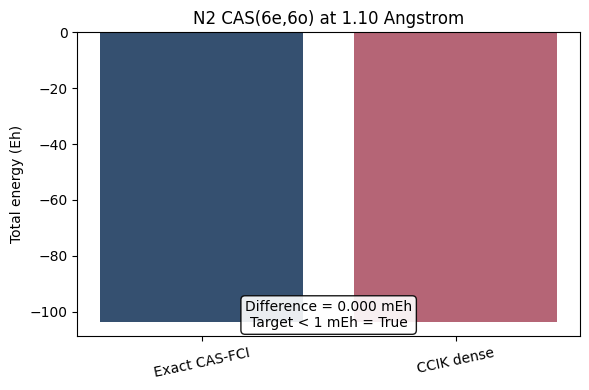

{'distance_ang': 1.1,
 'ncas': 6.0,
 'nelecas': 6.0,
 'solver_name': 'ccik_dense',
 'solver_label': 'CCIK dense',
 'target_millihartree': 1.0,
 'meets_target': True,
 'e_fci_total': -103.61031380829588,
 'e_dense_total': -103.61031380829588,
 'e_ccik_total': -103.61031380829588,
 'delta_millihartree': 0.0}

In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "examples" / "scripts").exists():
    repo_root = repo_root.parent.parent
script_path = repo_root / "examples" / "scripts" / "03_n2_intro_active_space.py"
spec = importlib.util.spec_from_file_location("n2_example", script_path)
module = importlib.util.module_from_spec(spec)
assert spec is not None and spec.loader is not None
spec.loader.exec_module(module)

result = module.run_example()

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Exact CAS-FCI", result["solver_label"]]
energies = [result["e_fci_total"], result["e_ccik_total"]]
colors = ["#355070", "#b56576"]
ax.bar(labels, energies, color=colors)
ax.set_ylabel("Total energy (Eh)")
ax.set_title(f"N2 CAS(6e,6o) at {result['distance_ang']:.2f} Angstrom")
ax.text(
    0.5,
    0.03,
    f"Difference = {result['delta_millihartree']:.3f} mEh\nTarget < 1 mEh = {result['meets_target']}",
    transform=ax.transAxes,
    ha="center",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()
result

## Large-N2 benchmark appendix

The small `CAS(6e,6o)` example above is only the teaching entry point. The current large-active-space production answer in this repo is:

- Quantum Package backend
- `connected_sd_fullq`
- `abs_residual`
- `ccik_thick`
- `fixed_budget` compression

Best completed benchmark points so far:

- `N2 / CAS(12e,12o)`: `fixed_store_keep = 65536`, `fixed_propagate_keep = 2048`, `|ΔE| = 0.000779 mEh` vs `DMRG`
- `N2 / CAS(14e,14o)`: `fixed_store_keep = 65536`, `fixed_propagate_keep = 1024`, `|ΔE| = 0.712248 mEh` vs `Exact FCI`

The consolidated figure below shows why the tuning strategy is to keep `fixed_store_keep` moderate and tune `fixed_propagate_keep` first.

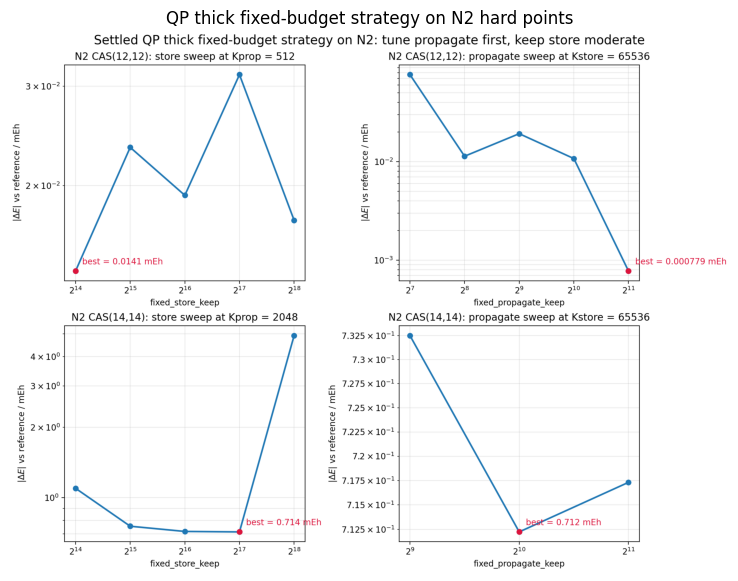

In [2]:
summary_path = repo_root / 'docs' / 'assets' / 'figures' / 'n2_fixed_budget_strategy_summary.png'
summary_image = plt.imread(summary_path)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(summary_image)
ax.axis('off')
ax.set_title('QP thick fixed-budget strategy on N2 hard points')
plt.show()